In [5]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

In [6]:
# 1. SIMULATE MESSY SMARTWATCH DATA (6 READINGS IN 24 HOURS)
# ---------------------------------------------------------
torch.manual_seed(42)

# Patient's true daily rhythm: Average 36.8°C, swings ±0.4°C, peaks at 4:00 PM (16:00)
TRUE_MESOR = 36.8
TRUE_AMPLITUDE = 0.4
TRUE_PEAK_HOUR = 16.0
OMEGA = 2 * np.pi / 24.0  # Sets the rhythm to repeat every 24 hours

# Smartwatch takes only 6 uneven, slightly noisy temperature readings
sample_hours = torch.tensor([[2.0], [6.5], [10.0], [14.5], [19.0], [22.5]])
true_temps_at_samples = TRUE_MESOR + TRUE_AMPLITUDE * torch.cos(OMEGA * (sample_hours - TRUE_PEAK_HOUR))
noisy_readings = true_temps_at_samples + torch.randn_like(sample_hours) * 0.05

In [7]:
# 2. BUILD A TINY NEURAL NETWORK
# ---------------------------------------------------------
# Input: Hour of the day (0 to 24) -> Output: Body Temperature (°C)
model = nn.Sequential(
    nn.Linear(1, 32),
    nn.Tanh(),
    nn.Linear(32, 32),
    nn.Tanh(),
    nn.Linear(32, 1)
)

# Let the AI also discover the patient's daily average baseline (MESOR)
estimated_mesor = nn.Parameter(torch.tensor([37.0]))
optimizer = torch.optim.Adam(list(model.parameters()) + [estimated_mesor], lr=0.01)

# 200 checkpoints across the entire 24-hour day
day_hours = torch.linspace(0, 24, 200).view(-1, 1)
day_hours.requires_grad = True

In [8]:
# 3. TRAIN THE AI USING CIRCADIAN WAVE RULES
# ---------------------------------------------------------
print("Training the Circadian Rhythm AI...")

for step in range(3001):
    optimizer.zero_grad()

    # RULE 1: Match the 6 smartwatch readings we actually collected
    predicted_samples = model(sample_hours)
    data_error = torch.mean((predicted_samples - noisy_readings) ** 2)

    # RULE 2: Follow a smooth 24-hour biological wave (Cosinor Physics Rule)
    temp_curve = model(day_hours)

    # PyTorch calculates how fast temperature is rising/falling (1st derivative)
    speed = torch.autograd.grad(temp_curve, day_hours, torch.ones_like(temp_curve), create_graph=True)[0]
    # PyTorch calculates how the wave curves back toward the average (2nd derivative)
    curvature = torch.autograd.grad(speed, day_hours, torch.ones_like(speed), create_graph=True)[0]

    # Wave rule: Any smooth 24-hour cosine wave obeys this natural balance
    wave_rule_error = torch.mean((curvature + (OMEGA ** 2) * (temp_curve - estimated_mesor)) ** 2)

    # Combine both rules and update the AI
    total_error = (10.0 * data_error) + wave_rule_error
    total_error.backward()
    optimizer.step()

    # 3. TRAIN THE AI USING CIRCADIAN WAVE RULES
# ---------------------------------------------------------
print("Training the Circadian Rhythm AI...")

for step in range(3001):
    optimizer.zero_grad()

    # RULE 1: Match the 6 smartwatch readings we actually collected
    predicted_samples = model(sample_hours)
    data_error = torch.mean((predicted_samples - noisy_readings) ** 2)

    # RULE 2: Follow a smooth 24-hour biological wave (Cosinor Physics Rule)
    temp_curve = model(day_hours)

    # PyTorch calculates how fast temperature is rising/falling (1st derivative)
    speed = torch.autograd.grad(temp_curve, day_hours, torch.ones_like(temp_curve), create_graph=True)[0]
    # PyTorch calculates how the wave curves back toward the average (2nd derivative)
    curvature = torch.autograd.grad(speed, day_hours, torch.ones_like(speed), create_graph=True)[0]

    # Wave rule: Any smooth 24-hour cosine wave obeys this natural balance
    wave_rule_error = torch.mean((curvature + (OMEGA ** 2) * (temp_curve - estimated_mesor)) ** 2)

    # Combine both rules and update the AI
    total_error = (10.0 * data_error) + wave_rule_error
    total_error.backward()
    optimizer.step()

Training the Circadian Rhythm AI...
Training the Circadian Rhythm AI...



--- COSINOR RHYTHM REPORT ---
Daily Average (MESOR): 36.80 °C  (True: 36.80 °C)
Rhythm Strength (Amp): ±0.38 °C (True: ±0.40 °C)
Daily Peak Time:       15.3 hrs (True: 16.0 hrs / 4:00 PM)


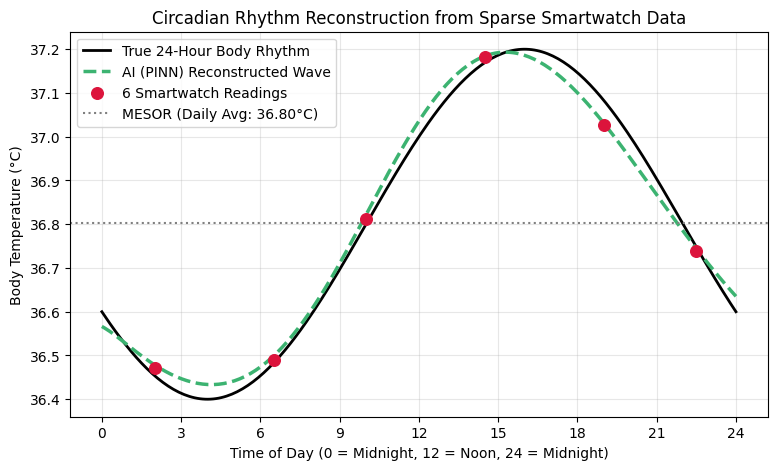

In [9]:
# 4. CALCULATE COSINOR METRICS & PLOT THE WAVE
# ---------------------------------------------------------
test_hours = torch.linspace(0, 24, 240).view(-1, 1)
with torch.no_grad():
    ai_curve = model(test_hours).numpy().flatten()

true_curve = (TRUE_MESOR + TRUE_AMPLITUDE * torch.cos(OMEGA * (test_hours - TRUE_PEAK_HOUR))).numpy().flatten()

# Extract Cosinor Health Metrics from the AI's wave
ai_mesor = np.mean(ai_curve)
ai_amplitude = (np.max(ai_curve) - np.min(ai_curve)) / 2
ai_peak_hour = test_hours.numpy().flatten()[np.argmax(ai_curve)]

print("\n--- COSINOR RHYTHM REPORT ---")
print(f"Daily Average (MESOR): {ai_mesor:.2f} °C  (True: {TRUE_MESOR:.2f} °C)")
print(f"Rhythm Strength (Amp): ±{ai_amplitude:.2f} °C (True: ±{TRUE_AMPLITUDE:.2f} °C)")
print(f"Daily Peak Time:       {ai_peak_hour:.1f} hrs (True: {TRUE_PEAK_HOUR:.1f} hrs / 4:00 PM)")

# Plot the 24-hour circadian rhythm
plt.figure(figsize=(9, 5))
plt.plot(test_hours.numpy(), true_curve, label="True 24-Hour Body Rhythm", color="black", linewidth=2)
plt.plot(test_hours.numpy(), ai_curve, label="AI (PINN) Reconstructed Wave", color="mediumseagreen", linestyle="--", linewidth=2.5)
plt.scatter(sample_hours.numpy(), noisy_readings.numpy(), color="crimson", s=70, zorder=5, label="6 Smartwatch Readings")
plt.axhline(ai_mesor, color="gray", linestyle=":", label=f"MESOR (Daily Avg: {ai_mesor:.2f}°C)")

plt.title("Circadian Rhythm Reconstruction from Sparse Smartwatch Data")
plt.xlabel("Time of Day (0 = Midnight, 12 = Noon, 24 = Midnight)")
plt.ylabel("Body Temperature (°C)")
plt.xticks(range(0, 25, 3))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()